# Imports

##### standard python libraries

In [1]:
import polars as pl
import adbc_driver_postgresql.dbapi as adbc_api
import re

import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon
import matplotlib.cm as cm

In [2]:
import warnings
warnings.filterwarnings('ignore')

##### Custom Libraries

In [3]:
import psql_utilities as psql_utl
#import matplotlib_utilities as plot_utl

### Set Paths

In [4]:
### path to configuration file of database
path_conf_file = './../../config/database.ini'

### Database Connection

In [5]:
db_config = psql_utl.load_config(path_conf_file)
### connect to the databse (polars adbc)
conn = adbc_api.connect(db_config['db_uri'])

## Retrieve simulation run parameters

In this notebook, we use simulation run parameters to plot the magnitude distribution of simulated scenarios for each seismicity type.

### setup

##### read query from file

In [6]:
query_params_ps = open("./query_params.sql", "r")
query_params_ps = query_params_ps.read()

### query result

##### run query with polars

In [7]:
df_sr_params = pl.read_database_uri(query_params_ps,engine='connectorx',uri=db_config['db_uri'],partition_num=6)
df_sr_params

sr_id,sr_path,scen_name,fk_sr_id,seismicity_type,magnitude,manning_coeff,fault_centre_lon,fault_centre_lat,fault_centre_depth,fault_lenght,fault_width,strike,dip,rake,slip,mesh_fault_bc_lon,mesh_fault_bc_lat,mesh_fault_rake_uniform,mesh_fault_slip_avg,max_ts_ct,max_ts_sr,arrival_time_min_ct,arrival_time_min_sr
str,str,str,str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""sr_9""","""CT-SR_M100/BS_001/E01470N3877E…","""E01470N3877E01631N3641-BS-M707…","""sr_9""","""BS""",7.07,0.01,15.3446,37.6022,9.135,50.10488,23.85,22.5,50.0,270.0,1.302045,null,null,null,null,0.492235,0.10374,6.508274,13.004539
"""sr_11""","""CT-SR_M100/BS_001/E01267N3753E…","""E01267N3753E01646N3535-BS-M774…","""sr_11""","""BS""",7.74,0.01,15.5157,36.9278,17.709,113.440739,27.677,157.5,30.0,90.0,5.040772,null,null,null,null,0.938407,1.814615,4.010633,2.005317
"""sr_12""","""CT-SR_M100/BS_001/E01470N3877E…","""E01470N3877E01631N3641-BS-M754…","""sr_12""","""BS""",7.54,0.01,15.3446,37.6022,14.081,95.874621,36.762,292.5,50.0,270.0,2.23657,null,null,null,null,1.028843,0.38083,9.510244,6.508273
"""sr_16""","""CT-SR_M100/BS_001/E01267N3753E…","""E01267N3753E01646N3535-BS-M732…","""sr_16""","""BS""",7.32,0.01,15.479,36.7029,7.167,63.069594,18.712,157.5,50.0,90.0,3.089911,null,null,null,null,0.279795,0.452258,11.011229,1.008662
"""sr_25""","""CT-SR_M100/BS_001/E01108N3882E…","""E01108N3882E01527N3690-BS-M732…","""sr_25""","""BS""",7.32,0.01,15.0608,37.6022,23.044,70.438555,29.931,292.5,50.0,90.0,1.72964,null,null,null,null,0.607877,0.1121,0.0,6.003942
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""sr_481857""","""CT-SR_M100/PS_009/E02020N3739E…","""E02020N3739E02658N3366-PS-Mur_…","""sr_481857""","""PS""",8.95,0.09,null,null,null,null,null,null,null,null,null,23.86,34.81,90.0,8.146623,2.023531,1.504674,56.001412,51.006165
"""sr_481901""","""CT-SR_M100/PS_009/E02020N3739E…","""E02020N3739E02658N3366-PS-Str_…","""sr_481901""","""PS""",8.88,0.09,null,null,null,null,null,null,null,null,null,24.51,34.5,90.0,8.920498,0.876634,0.670558,67.505965,61.502222
"""sr_481864""","""CT-SR_M100/PS_009/E02020N3739E…","""E02020N3739E02658N3366-PS-Str_…","""sr_481864""","""PS""",8.95,0.09,null,null,null,null,null,null,null,null,null,23.18,34.71,90.0,10.233136,1.598934,1.252442,58.510518,54.007707


### Events Stats

##### Magnitude Distribution per Sismicity Type

In [8]:
### aggregate simulation runs per magnitude bin
df_mag_stats = df_sr_params.select('scen_name','seismicity_type','magnitude').unique()\
                           .group_by('seismicity_type','magnitude')\
                           .agg(pl.col('scen_name').count().alias('num_scen'))
df_mag_stats = df_mag_stats.pivot(values='num_scen',index='magnitude',columns='seismicity_type')\
                           .fill_null(0)\
                           .sort('magnitude') 
df_mag_stats
### we approzimate the magnitude to 0.5
list_bins = [6.25, 6.75, 7.25, 7.75, 8.25, 8.75, 9.25, 9.75, 10]
list_labels = ['6','6.5','7','7.5','8','8.5','9','9.5','10','999']
df_mag_stats = df_mag_stats.with_columns(pl.col('magnitude').cut(breaks=list_bins,labels=list_labels).cast(pl.String).cast(pl.Float64).alias('mag_label'))
with pl.Config(tbl_rows=-1):
    print(df_mag_stats) 
df_mag_stats = df_mag_stats.group_by('mag_label')\
                            .agg(pl.col('BS').sum(),
                                 pl.col('PS').sum())\
                            .sort(by='mag_label')
print(df_mag_stats)

shape: (18, 4)
┌───────────┬──────┬──────┬───────────┐
│ magnitude ┆ PS   ┆ BS   ┆ mag_label │
│ ---       ┆ ---  ┆ ---  ┆ ---       │
│ f64       ┆ u32  ┆ u32  ┆ f64       │
╞═══════════╪══════╪══════╪═══════════╡
│ 6.0       ┆ 0    ┆ 4    ┆ 6.0       │
│ 6.5       ┆ 10   ┆ 283  ┆ 6.5       │
│ 6.8       ┆ 138  ┆ 1087 ┆ 7.0       │
│ 7.07      ┆ 351  ┆ 2449 ┆ 7.0       │
│ 7.32      ┆ 704  ┆ 3376 ┆ 7.5       │
│ 7.54      ┆ 1197 ┆ 4603 ┆ 7.5       │
│ 7.74      ┆ 1555 ┆ 4290 ┆ 7.5       │
│ 7.92      ┆ 2104 ┆ 4952 ┆ 8.0       │
│ 8.09      ┆ 2043 ┆ 3997 ┆ 8.0       │
│ 8.24      ┆ 2062 ┆ 0    ┆ 8.0       │
│ 8.37      ┆ 1753 ┆ 0    ┆ 8.5       │
│ 8.5       ┆ 1544 ┆ 0    ┆ 8.5       │
│ 8.61      ┆ 5581 ┆ 0    ┆ 8.5       │
│ 8.71      ┆ 3774 ┆ 0    ┆ 8.5       │
│ 8.8       ┆ 2335 ┆ 0    ┆ 9.0       │
│ 8.88      ┆ 1612 ┆ 0    ┆ 9.0       │
│ 8.95      ┆ 1076 ┆ 0    ┆ 9.0       │
│ 9.02      ┆ 670  ┆ 0    ┆ 9.0       │
└───────────┴──────┴──────┴───────────┘
shape: (7, 3)
┌──────────

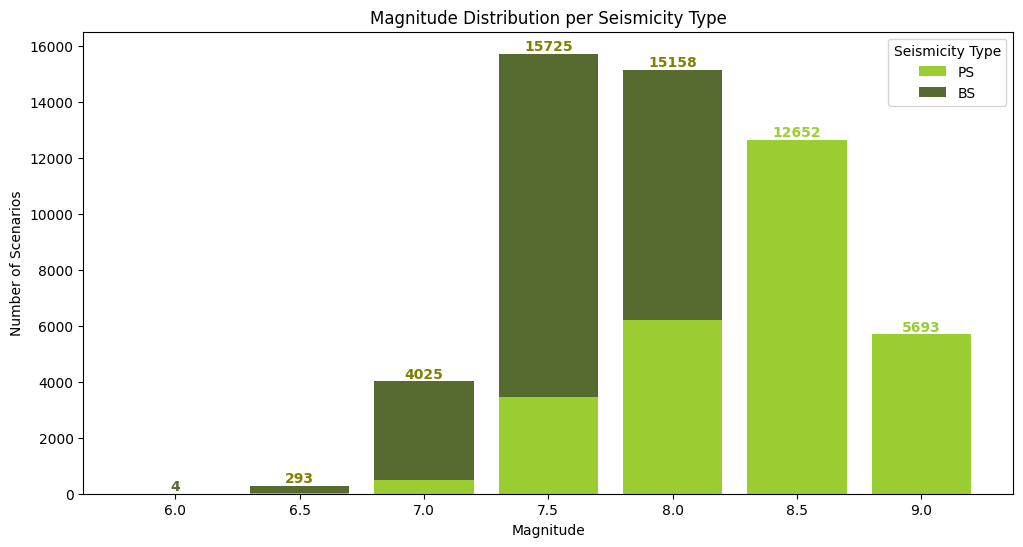

In [9]:
### plot histogram of magnitude distribution

fig, ax = plt.subplots(figsize=(12, 6))

magnitude_values = df_mag_stats['mag_label'].cast(pl.String)
list_ps_scen = df_mag_stats['PS']
list_bs_scen = df_mag_stats['BS']

bar_ps = ax.bar(magnitude_values, list_ps_scen, color='yellowgreen', label='PS')
bar_bs = ax.bar(magnitude_values, list_bs_scen, bottom=list_ps_scen, color='darkolivegreen', label='BS')

label_color = 'black'
for i, (ps_val, bs_val) in enumerate(zip(list_ps_scen, list_bs_scen)):
    total = ps_val + bs_val
    #
    if bs_val == 0:
        label_color = 'yellowgreen'
    elif ps_val == 0:
        label_color = 'darkolivegreen'
    else:
        label_color = 'olive'
    #
    ax.text(magnitude_values[i], total, f'{total}', 
            ha='center', va='bottom', fontweight='bold',color=label_color)

ax.set_xlabel('Magnitude',)
ax.set_ylabel('Number of Scenarios')
ax.legend(title='Seismicity Type')
ax.set_title('Magnitude Distribution per Seismicity Type')
ax.set_xticks(magnitude_values)